V26B.ART Artifact Classification DL Model
Developed by M. Chaney, 2026

In [1]:
import os
import cv2
import matplotlib.pyplot as plt
import random
from PIL import Image
import torch
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import torchvision.models as models
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import joblib
from tqdm import tqdm
import numpy as np

In [2]:
# folder paths
dataset_path = r'C:/Users/Owner/Documents/Lagoon_Public_Art_V26B/Photos/Condition_Assessment'

# training directory
train_dir = os.path.join(dataset_path, 'Train')

# file names
classes = os.listdir(train_dir)

In [3]:
transform = transforms.Compose([
	transforms.Resize((400,400)),
	transforms.ToTensor(),
    # transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [4]:
from torch.utils.data import Dataset

class MultiFolderDataset(Dataset):
    def __init__(self, root, transform=None, attributes=None):
        self.transform = transform
        self.attributes = attributes or sorted(
            d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))
        )
        self.class_names = {}
        entries = {}  # filename -> {'path': ..., attr: label_idx}

        for attr in self.attributes:
            folder = ImageFolder(os.path.join(root, attr))
            self.class_names[attr] = folder.classes
            for path, idx in folder.samples:
                entry = entries.setdefault(os.path.basename(path), {'path': path})
                entry[attr] = idx

        # keep only images that have a label in every data folder
        self.samples = [
            (e['path'], [e[a] for a in self.attributes])
            for e in entries.values()
            if all(a in e for a in self.attributes)
        ]
        dropped = len(entries) - len(self.samples)
        if dropped:
            print(f"Warning: {dropped} images dropped (missing from some data folders)")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        path, labels = self.samples[i]
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(labels)

train_dataset = MultiFolderDataset(os.path.join(dataset_path, 'Train'), transform)
attributes = train_dataset.attributes
val_dataset = MultiFolderDataset(os.path.join(dataset_path, 'Val'), transform, attributes)
test_dataset = MultiFolderDataset(os.path.join(dataset_path, 'Test'), transform, attributes)

print(attributes)
print(len(train_dataset), len(val_dataset), len(test_dataset))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

['BC_Data', 'Crack_Data', 'Deform_Data', 'Deposit_Data', 'Detach_Data', 'Discolor_Data', 'MatLoss_Data']
86 46 46


In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class MultiHeadResNet(nn.Module):
    def __init__(self, class_counts):
        super().__init__()
        self.backbone = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        for p in self.backbone.parameters():
            p.requires_grad = False
        feat = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()

        self.heads = nn.ModuleList([
            nn.Sequential(nn.Linear(feat, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, n))
            for n in class_counts
        ])

    def forward(self, x):
        f = self.backbone(x)
        return [head(f) for head in self.heads]   # list of 7 tensors, each (batch, 6)

resnet_num = '50'
class_counts = [len(train_dataset.class_names[a]) for a in attributes]
model = MultiHeadResNet(class_counts).to(device)

optimizer = optim.Adam(model.heads.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

In [6]:
def train_one_epoch(model, loader):
    model.train()
    running_loss = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = sum(criterion(out, labels[:, i]) for i, out in enumerate(outputs))
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    return running_loss / len(loader)

In [7]:
def evaluate(model, loader):
    model.eval()
    correct = torch.zeros(len(attributes))
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            for i, out in enumerate(outputs):
                correct[i] += (out.argmax(1) == labels[:, i]).sum().item()
            total += labels.size(0)

    return (correct / total).tolist()   # one accuracy per data folder

In [9]:
epochs = 30
for epoch in tqdm(range(epochs)):
    train_loss = train_one_epoch(model, train_loader)
    val_accs = evaluate(model, val_loader)
    print(f"Epoch {epoch+1}, Train Loss: {train_loss:.4f}")
    for a, acc in zip(attributes, val_accs):
        print(f"   {a}: {acc:.4f}")

  3%|▎         | 1/30 [00:21<10:17, 21.28s/it]

Epoch 1, Train Loss: 8.8377
   BC_Data: 0.5870
   Crack_Data: 0.4565
   Deform_Data: 0.8696
   Deposit_Data: 0.3913
   Detach_Data: 0.6739
   Discolor_Data: 0.4783
   MatLoss_Data: 0.3913


  7%|▋         | 2/30 [00:42<09:53, 21.19s/it]

Epoch 2, Train Loss: 7.5096
   BC_Data: 0.5435
   Crack_Data: 0.5652
   Deform_Data: 0.8696
   Deposit_Data: 0.4783
   Detach_Data: 0.6739
   Discolor_Data: 0.5217
   MatLoss_Data: 0.5217


 10%|█         | 3/30 [01:03<09:32, 21.20s/it]

Epoch 3, Train Loss: 6.5334
   BC_Data: 0.5435
   Crack_Data: 0.6739
   Deform_Data: 0.8696
   Deposit_Data: 0.5652
   Detach_Data: 0.6739
   Discolor_Data: 0.5217
   MatLoss_Data: 0.5870


... (50 outputs left out)

 97%|█████████▋| 29/30 [10:14<00:21, 21.20s/it]

Epoch 29, Train Loss: 0.1936
   BC_Data: 1.0000
   Crack_Data: 1.0000
   Deform_Data: 1.0000
   Deposit_Data: 1.0000
   Detach_Data: 1.0000
   Discolor_Data: 1.0000
   MatLoss_Data: 1.0000


100%|██████████| 30/30 [10:35<00:00, 21.19s/it]

Epoch 30, Train Loss: 0.1622
   BC_Data: 1.0000
   Crack_Data: 1.0000
   Deform_Data: 1.0000
   Deposit_Data: 1.0000
   Detach_Data: 1.0000
   Discolor_Data: 1.0000
   MatLoss_Data: 1.0000


In [10]:
test_accs = evaluate(model, test_loader)
for a, acc in zip(attributes, test_accs):
    print(f"Test {a}: {acc:.4f}")

Test BC_Data: 1.0000
Test Crack_Data: 1.0000
Test Deform_Data: 1.0000
Test Deposit_Data: 1.0000
Test Detach_Data: 1.0000
Test Discolor_Data: 1.0000
Test MatLoss_Data: 1.0000


In [12]:
from sklearn.metrics import confusion_matrix, classification_report

In [13]:
def collect_predictions(model, loader):
    model.eval()
    preds, labs = [], []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            preds.append(torch.stack([o.argmax(1) for o in outputs], dim=1).cpu())
            labs.append(labels)
    return torch.cat(labs).numpy(), torch.cat(preds).numpy()

all_labels, all_preds = collect_predictions(model, test_loader)   # both (N, 7)

for i, a in enumerate(attributes):
    names = train_dataset.class_names[a]
    print(f"\n=== {a} ===")
    print(classification_report(
        all_labels[:, i], all_preds[:, i],
        labels=list(range(len(names))),
        target_names=names,
        zero_division=0,
    ))


=== BC_Data ===
              precision    recall  f1-score   support

        BC_0       1.00      1.00      1.00        18
        BC_1       1.00      1.00      1.00        17
        BC_2       1.00      1.00      1.00         5
        BC_3       1.00      1.00      1.00         2
        BC_4       1.00      1.00      1.00         3
        BC_5       1.00      1.00      1.00         1

    accuracy                           1.00        46
   macro avg       1.00      1.00      1.00        46
weighted avg       1.00      1.00      1.00        46


=== Crack_Data ===
              precision    recall  f1-score   support

     Crack_0       1.00      1.00      1.00        21
     Crack_1       1.00      1.00      1.00        17
     Crack_2       1.00      1.00      1.00         4
     Crack_3       1.00      1.00      1.00         4
     Crack_4       0.00      0.00      0.00         0

    accuracy                           1.00        46
   macro avg       0.80      0.80      0

In [ ]:

# collect all preds/labels from test_loader, then:
# print(classification_report(all_labels, all_preds, target_names=test_dataset.classes))

In [14]:
def visualize_predictions(model, loader, n=5):
    model.eval()
    images_shown = 0

    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            preds = torch.stack([o.argmax(1) for o in outputs], dim=1).cpu()

            for i in range(images.size(0)):
                img = images[i].permute(1, 2, 0).numpy()
                lines = []
                for j, a in enumerate(attributes):
                    names = train_dataset.class_names[a]
                    t, p = names[labels[i, j]], names[preds[i, j]]
                    mark = '*' if t == p else 'x'
                    lines.append(f'{a}: {t} / {p} {mark}')

                plt.figure(figsize=(6, 6))
                plt.imshow(img)
                plt.title('True / Pred\n' + '\n'.join(lines), fontsize=9)
                plt.axis('off')
                plt.show()

                images_shown += 1
                if images_shown >= n:
                    return

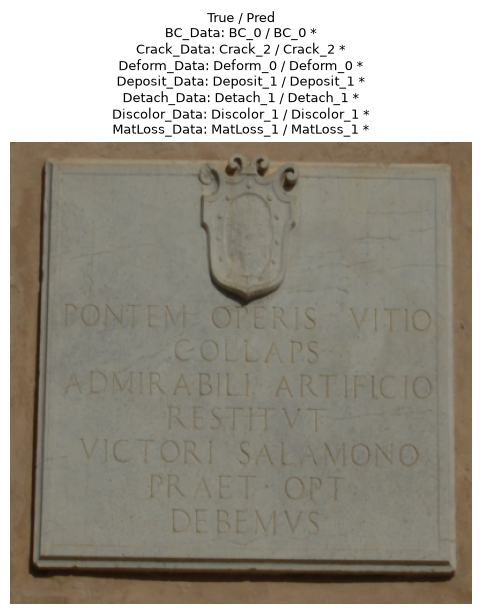

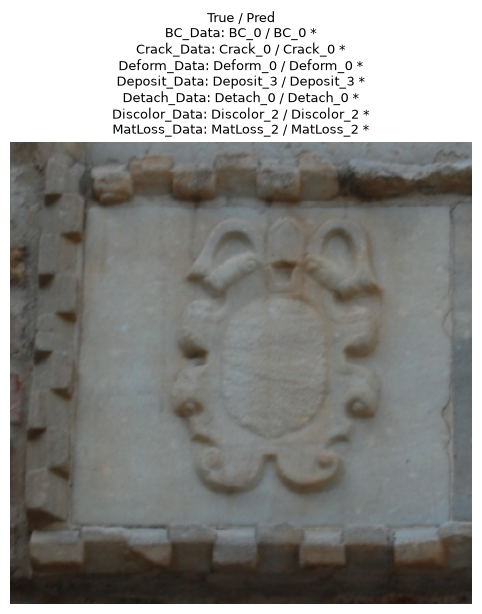

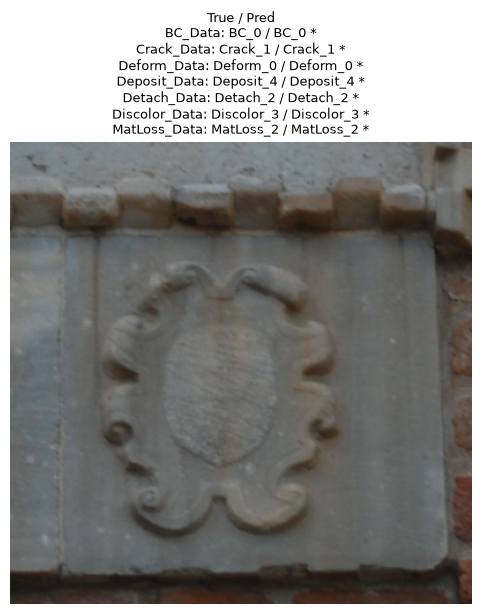

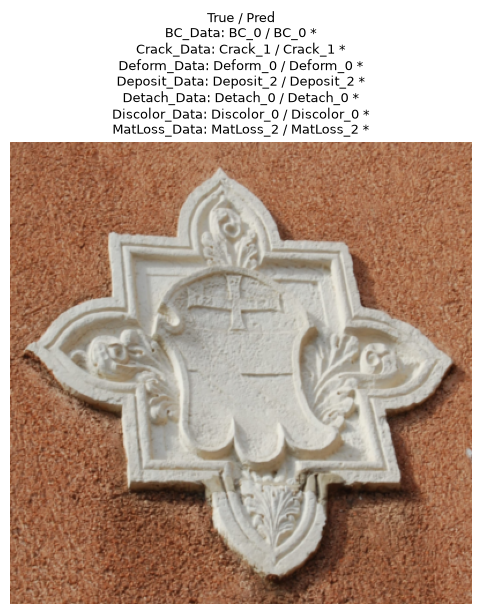

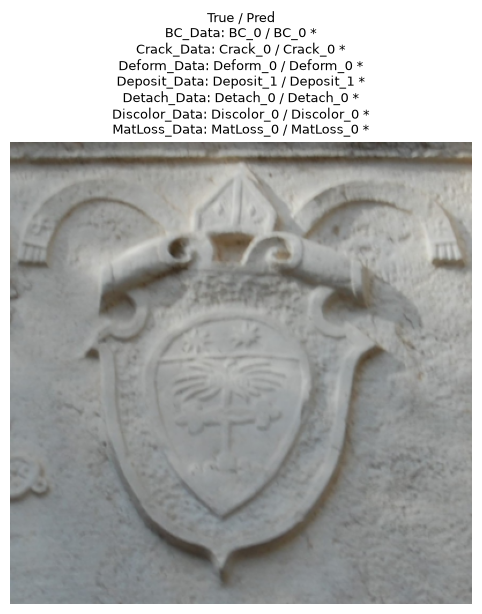

In [15]:
visualize_predictions(model, test_loader, 5)

In [16]:
model_data = {
    'model_state_dict': model.state_dict(),
    'attributes': attributes,
    'class_names': train_dataset.class_names,
}

In [17]:
joblib.dump(model_data, f'condition_assessment_model_resnet{resnet_num}.pkl')

['condition_assessment_model_resnet50.pkl']